# Notebook 06: Evaluation and deployment check

Notebooks 01 to 05 trained the models and reported results on **one** set of held-out wafers. This notebook asks the
questions a test engineer would ask before trusting them:

| Part | Question | How it is checked |
|---|---|---|
| 1 | **Is the result stable from wafer to wafer?** | Leave-one-wafer-out: every wafer is held out once, the model is retrained on the others |
| 2 | **Was each choice tuned for the real goal?** | Trims tuned for test time; the SoC safety margin chosen on *validation* wafers, then checked on untouched wafers |
| 3 | **Does the method beat today's way, task by task?** | One table: baseline vs method vs decision |
| 4 | **What happens with unusual or borderline chips?** | An out-of-range check, fallback rates, and speed-testing only the chips the AI is unsure about |
| 5 | **How would it run on a tester?** | Loading the saved models, one decision function, speed per chip, monitoring, model cards |

> **All data in this project is synthetic.** These checks show the methods work on the generated datasets. They can't
> prove the methods work on real fab data; that needs the same checks on real wafers, in shadow mode.

**Colab:** Runtime → Run all. Upload the dataset zip (or the 5 CSVs) and the 4 model files saved by notebooks 01-04
(`trim_models.joblib`, `pmic_models.joblib`, `sensor_models.joblib`, `soc_models.joblib`). Part 1 retrains the models
once per wafer, so a full run takes about 10 minutes on Colab.

## 0.1 Setup

In [1]:
import importlib.metadata as im, subprocess, sys
if im.version("scikit-learn") != "1.9.0":  # the saved models were made with scikit-learn 1.9.0
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn==1.9.0"])
    print("Installed scikit-learn 1.9.0. In Colab: Runtime -> Restart session, then Run all again.")

import copy, glob, json, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.stats import beta
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
TEAL, COPPER, SLATE, GREY, INK = "#0F766E", "#B4581E", "#3F5E7A", "#9AA19C", "#1E2B2A"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .3,
                     "axes.titleweight": "bold", "axes.titlecolor": INK, "font.size": 10})
SEED = 42
print("Libraries loaded | scikit-learn", im.version("scikit-learn"))

Libraries loaded | scikit-learn 1.9.0


## 0.2 Load the data and the saved models

In [2]:
CSVS = ["mcu_trim_fuse.csv", "pmic_trim_otp.csv", "sensor_calibration.csv", "soc_binning_harvesting.csv", "soc_sku_demand.csv"]
MODEL_FILES = ["trim_models.joblib", "pmic_models.joblib", "sensor_models.joblib", "soc_models.joblib"]

def find(name):
    hits = [h for h in glob.glob(f"**/{name}", recursive=True) if "cleaned" not in h]
    return min(hits, key=len) if hits else None

missing = [f for f in CSVS + MODEL_FILES if find(f) is None]
if missing:
    try:
        from google.colab import files
        print("Upload the dataset zip and the 4 .joblib files. Missing:", missing)
        for fname in files.upload():
            if fname.lower().endswith(".zip"):
                zipfile.ZipFile(fname).extractall("dataset_upload")
    except ImportError:
        raise FileNotFoundError(f"Put {missing} next to this notebook")

mcu, pmic, sensor, soc_raw, sku = (pd.read_csv(find(f)) for f in CSVS)
TRIM, PMIC_B, SENS_B, SOC_B = (joblib.load(find(f)) for f in MODEL_FILES)
print({n: d.shape for n, d in zip(["mcu", "pmic", "sensor", "soc", "sku"], [mcu, pmic, sensor, soc_raw, sku])})
print("Wafers per product:", {d: n for x in (mcu, pmic, sensor) for d, n in x.groupby("derivative").wafer_id.nunique().items()})

{'mcu': (8420, 42), 'pmic': (11060, 63), 'sensor': (11060, 67), 'soc': (6160, 52), 'sku': (3, 6)}
Wafers per product: {'MCU-A': 15, 'MCU-B': 3, 'MCU-C': 2, 'PMIC-C7': 2, 'PMIC-P1': 15, 'PMIC-P2': 3, 'ACC-16G': 2, 'ACC-2G': 15, 'ACC-8G': 3}


## 0.3 Shared helpers (the same code as notebooks 01-04)
* **Split:** whole wafers are held out (25 %, seed 42), never single chips.
* **Predict, then check:** the tester sets the predicted code and measures once. Exact: 1 measurement. One step off:
  one more (2 in total). Further off: today's binary search (1 + number of bits). `budget` is how many extra steps
  the tester may try before falling back; notebooks 01-04 used `budget=1`.

In [3]:
PCM = ["pcm_vth_n_mV", "pcm_vth_p_mV", "pcm_rs_ohm_sq", "pcm_tox_A", "pcm_mobility_rel"]
POS = ["x_mm", "y_mm", "radius_mm"]

def wafer_split(df, test_size=0.25, seed=SEED):
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed).split(df, groups=df.wafer_id))
    return df.iloc[tr].reset_index(drop=True), df.iloc[te].reset_index(drop=True)

def to_code(pred, bits):
    return np.clip(np.round(pred), 0, 2 ** bits - 1).astype(int)

def tries(err, bits, budget=1):
    err = np.abs(np.asarray(err))
    return np.where(err <= budget, 1 + err, 1 + bits)

def upper95(k, n):
    # Clopper-Pearson: with k events in n chips, the true rate is below this with 95 % confidence
    return beta.ppf(0.95, k + 1, n - k) if n else np.nan

# ---------------- MCU (notebook 01)
TRIMS = {"bg": dict(name="Bandgap", label="bg_trim_code_opt", untrim="bg_untrim_V", bits=6, mid=32, target=1.200,
                    lsb=0.002, mult=False, conv="bg_conv_iterations", ms=1.2),
         "hsi": dict(name="HSI clock", label="hsi_trim_code_opt", untrim="hsi_untrim_MHz", bits=7, mid=64, target=16.0,
                     lsb=0.002, mult=True, conv="hsi_conv_iterations", ms=2.0),
         "ldo": dict(name="LDO", label="ldo_trim_code_opt", untrim="ldo_untrim_V", bits=5, mid=16, target=1.10,
                     lsb=0.005, mult=False, conv="ldo_conv_iterations", ms=1.0)}

def mcu_formula(d, t):
    c = TRIMS[t]; u = d[c["untrim"]].values
    return c["mid"] + (c["target"] / u - 1) / c["lsb"] if c["mult"] else c["mid"] - (u - c["target"]) / c["lsb"]

def mcu_features(df):
    d = df.copy()
    for t, c in TRIMS.items():
        d[f"{t}_ideal_code"] = mcu_formula(d, t)
        d[f"{t}_err_from_target"] = d[c["untrim"]] - c["target"]
    return d

def mcu_errors(d, models, budget=1):
    # per chip: code error for each trim, plus tries and ms with predict-then-check
    out = pd.DataFrame(index=d.index)
    for t, c in TRIMS.items():
        out[t] = to_code(models[t].predict(d[TRIM[t]["features"]]), c["bits"]) - d[c["label"]].values
        out[f"{t}_formula"] = to_code(mcu_formula(d, t), c["bits"]) - d[c["label"]].values
    out["tries_ai"] = sum(tries(out[t], TRIMS[t]["bits"], budget) for t in TRIMS)
    out["ms_ai"] = sum(tries(out[t], TRIMS[t]["bits"], budget) * TRIMS[t]["ms"] for t in TRIMS)
    out["tries_today"] = sum(d[c["conv"]].values for c in TRIMS.values())
    out["ms_today"] = sum(d[c["conv"]].values * c["ms"] for c in TRIMS.values())
    out["no_search"] = np.all([np.abs(out[t]) <= 1 for t in TRIMS], axis=0)
    out["no_search_formula"] = np.all([np.abs(out[f"{t}_formula"]) <= 1 for t in TRIMS], axis=0)
    return out

# ---------------- PMIC (notebook 02)
RAILS = ["buck1", "buck2", "ldo1", "ldo2"]
THR = {"ovp": dict(label="ovp_trim_code_opt", untrim="ovp_untrim_V", bits=4, mid=8, lsb=0.005, target=3.63),
       "uvlo": dict(label="uvlo_trim_code_opt", untrim="uvlo_untrim_V", bits=4, mid=8, lsb=0.005, target=2.70),
       "ilim": dict(label="ilim_trim_code_opt", untrim="ilim_untrim_A", bits=5, mid=16, lsb=0.01, target=3.0)}

def pmic_features(df):
    d = df.copy()
    d["ref_ideal_code"] = 32 + (0.600 / d.vref_trimmed_sort_V - 1) / 0.002
    d["vref_err_mV"] = (d.vref_untrim_V - 0.600) * 1000
    return d

def pmic_errors(d, rails, vref, budget=1):
    out = pd.DataFrame(index=d.index)
    for r in RAILS:
        out[r] = to_code(rails[r].predict(d[PMIC_B["rails"][r]["features"]]), 6) - d[f"{r}_trim_code_opt"].values
    out["vref"] = to_code(vref.predict(d[PMIC_B["thresholds"]["vref"]["features"]]), 6) - d.vref_trim_code_opt.values
    thr = 0
    for t, c in THR.items():  # thresholds: the formula is already right, no model needed
        code_ = to_code(c["mid"] + (c["target"] / d[c["untrim"]].values - 1) / c["lsb"], c["bits"])
        thr = thr + tries(code_ - d[c["label"]].values, c["bits"])
    out["tries_ai"] = sum(tries(out[r], 6, budget) for r in RAILS) + tries(out["vref"], 6, budget) + thr
    out["tries_today"] = d.conv_trim_iterations.values
    out["no_search"] = np.all([np.abs(out[r]) <= 1 for r in RAILS], axis=0)
    return out

# ---------------- Sensor (notebook 03): one row per chip and axis
DIE = ["die_id", "wafer_id", "derivative", "package", "characterized_3temp", "stress_gauge_mV", "asic_vref_mV",
       "mems_resonance_kHz", "mems_q_factor", "conv_test_time_s"] + PCM + POS
PER_AXIS = {"st_response_{a}_mg": "st_response_mg", "offset_{a}_25C_mg": "offset_25C_mg", "sens_{a}_25C_rel": "sens_25C_rel",
            "offset_{a}_m40C_mg": "offset_m40C_mg", "offset_{a}_85C_mg": "offset_85C_mg", "sens_{a}_m40C_rel": "sens_m40C_rel",
            "sens_{a}_85C_rel": "sens_85C_rel", "tco_{a}_true_mg_per_C": "tco", "tco2_{a}_true_mg_per_C2": "tco2",
            "tcs_{a}_true_ppm_per_C": "tcs"}
COEFS = ["tco", "tcs", "tco2"]
GRADES = {"Tight": (10, 0.5), "Medium": (12, 1.0), "Loose": (15, 1.0)}  # offset limit mg, sensitivity limit %

def sensor_long(s):
    parts = []
    for i, a in enumerate("xyz"):
        p = s[DIE].copy(); p["axis"] = i
        for src, dst in PER_AXIS.items():
            p[dst] = s[src.format(a=a)]
        parts.append(p)
    d = pd.concat(parts, ignore_index=True)
    g = d.groupby("die_id")
    d["offset_25C_mean3"] = g.offset_25C_mg.transform("mean")
    d["sens_25C_mean3"] = g.sens_25C_rel.transform("mean")
    d["is_lga12"] = (d.package == "LGA12").astype(int)
    return d

def sensor_pass(d, coef, off_lim, sens_lim):
    ok = np.ones(len(d), bool)
    for t, s in [(-40, "m40C"), (85, "85C")]:
        dt = t - 25
        off = d[f"offset_{s}_mg"] - (d.offset_25C_mg + coef["tco"] * dt + coef["tco2"] * dt ** 2)
        sens = (d[f"sens_{s}_rel"] / (d.sens_25C_rel * (1 + coef["tcs"] * 1e-6 * dt)) - 1) * 100
        ok &= (np.abs(off) <= off_lim).values & (np.abs(sens) <= sens_lim).values
    return ok

# ---------------- SoC (notebook 04)
ORDER, KS = ["SoC-Pro", "SoC-Std", "SoC-Lite"], (8, 6, 4)
FCOLS = [f"core{i}_fmax_GHz" for i in range(8)]
PRICE = sku.set_index("sku").price_usd

def soc_prepare(df):
    d = df.copy()
    d["n_good_cores"] = d[FCOLS].notna().sum(axis=1)
    d["leak_hot_A"] = d.iddq_25C_mA * 22 / 1000
    fs = -np.sort(-d[FCOLS].fillna(-1).values, axis=1)
    for k in KS:
        d[f"f_top{k}"] = np.where(fs[:, k - 1] > 0, fs[:, k - 1], np.nan)
    d["ro_x_cpm"] = d.ro_freq_MHz / d.cpm_path_delay_ps
    d["log_iddq"] = np.log(d.iddq_25C_mA)
    return d

def eligibility(d, ftop, guard_ghz=0.0):
    s_, out = sku.set_index("sku"), {}
    for s in ORDER:
        k, f, tdp = int(s_.loc[s, "cores"]), s_.loc[s, "fmax_GHz"], s_.loc[s, "tdp_W"]
        fslow = ftop[k] - guard_ghz
        with np.errstate(invalid="ignore", divide="ignore"):
            v_need = 0.85 * (f / fslow) ** 0.8
            b = np.ceil((np.maximum(v_need, 0.76) - 0.75) / 0.0125 - 1e-9)
            vb = 0.75 + b * 0.0125
            p = k * 0.62 * (vb / 0.85) ** 2 * f + d.leak_hot_A.values * vb
            ok = d.l2_repairable.values & np.isfinite(fslow) & (v_need <= 0.90) & (p <= tdp)
        out[s], out[s + "_bin"] = ok, np.where(ok, b, -1)
    return pd.DataFrame(out, index=d.index)

def best_sku(el):
    return np.select([el[s].values for s in ORDER], ORDER, default="scrap")

def unsafe(assigned, pred_el, true_el):
    # sold as a product the chip can't really meet, or given a lower voltage bin than it needs
    assigned, bad = np.asarray(assigned), np.zeros(len(assigned), bool)
    for s in ORDER:
        m = assigned == s
        bad[m] = ~true_el[s].values[m] | (pred_el[s + "_bin"].values[m] < true_el[s + "_bin"].values[m])
    return bad

measured = lambda d: {k: d[f"f_top{k}"].values for k in KS}  # noqa: E731
def predicted(d, models):
    return {k: np.where(d[f"f_top{k}"].notna(), models[k].predict(d[SOC_B["features"]]), np.nan) for k in KS}

soc = soc_prepare(soc_raw)
print("Helpers ready")

Helpers ready


# Part 1: Is the result stable from wafer to wafer?
Each wafer of the main product is held out **once**: the model is retrained on all the other wafers (same settings
as the saved model) and scored on the held-out wafer. That gives one result per wafer, so we see the **range**, not just
one number. New chip versions with only 2-3 wafers are scored per wafer with the saved model, and flagged as early
results.

## 1.1 MCU: leave-one-wafer-out (15 wafers, 3 Random Forests per fold)

In [4]:
A = mcu_features(mcu[mcu.derivative == "MCU-A"].reset_index(drop=True))
_, A_test = wafer_split(A)
REPORTED_TEST = set(A_test.wafer_id)
t0, rows = time.time(), []
for w in sorted(A.wafer_id.unique()):
    tr, te = A[A.wafer_id != w], A[A.wafer_id == w]
    models = {t: clone(TRIM[t]["model"]).fit(tr[TRIM[t]["features"]], tr[c["label"]]) for t, c in TRIMS.items()}
    e = mcu_errors(te, models)
    rows.append({"wafer": w, "in_reported_test": w in REPORTED_TEST, "chips": len(te),
                 "no_search_%": e.no_search.mean() * 100, "formula_no_search_%": e.no_search_formula.mean() * 100,
                 "tries_today": e.tries_today.mean(), "tries_ai": e.tries_ai.mean(),
                 "ms_today": e.ms_today.mean(), "ms_ai": e.ms_ai.mean(),
                 **{f"{t}_within1_%": (np.abs(e[t]) <= 1).mean() * 100 for t in TRIMS}})
lowo_mcu = pd.DataFrame(rows)
lowo_mcu["speedup_x"] = lowo_mcu.ms_today / lowo_mcu.ms_ai
print(f"{len(lowo_mcu)} folds in {time.time() - t0:.0f} s\n")
print(lowo_mcu.round(2).to_string(index=False))

15 folds in 171 s

  wafer  in_reported_test  chips  no_search_%  formula_no_search_%  tries_today  tries_ai  ms_today  ms_ai  bg_within1_%  hsi_within1_%  ldo_within1_%  speedup_x
MA1-W01              True    421        78.62                57.96        19.81      5.09     28.75   8.09         99.76          78.86         100.00       3.55
MA1-W02             False    421        80.29                65.56        19.61      4.93     28.42   7.79         99.29          81.00         100.00       3.65
MA1-W03             False    421        74.82                47.74        19.75      5.49     28.62   8.88        100.00          74.82         100.00       3.22
MA1-W04             False    421        66.98                43.94        19.73      6.37     28.59   9.83         92.40          74.58          95.25       2.91
MA1-W05             False    421        83.37                69.83        19.87      4.77     28.86   7.45         99.52          83.85         100.00       3.88
MA2-W01  

## 1.2 Power chip: leave-one-wafer-out on PMIC-P1, plus each wafer of the two new versions

In [5]:
P1 = pmic_features(pmic[pmic.derivative == "PMIC-P1"].reset_index(drop=True))
_, P1_test = wafer_split(P1)
rows = []
for w in sorted(P1.wafer_id.unique()):
    tr, te = P1[P1.wafer_id != w], P1[P1.wafer_id == w]
    rails = {r: clone(PMIC_B["rails"][r]["model"]).fit(tr[PMIC_B["rails"][r]["features"]], tr[f"{r}_trim_code_opt"]) for r in RAILS}
    vref = clone(PMIC_B["thresholds"]["vref"]["model"]).fit(tr[PMIC_B["thresholds"]["vref"]["features"]], tr.vref_trim_code_opt)
    e = pmic_errors(te, rails, vref)
    rows.append({"product": "PMIC-P1", "wafer": w, "in_reported_test": w in set(P1_test.wafer_id), "chips": len(te),
                 "no_search_%": e.no_search.mean() * 100, "tries_today": e.tries_today.mean(), "tries_ai": e.tries_ai.mean()})
saved_rails = {r: PMIC_B["rails"][r]["model"] for r in RAILS}
NEW = pmic_features(pmic[pmic.derivative != "PMIC-P1"].reset_index(drop=True))
for (dv, w), te in NEW.groupby(["derivative", "wafer_id"]):  # never seen in training
    e = pmic_errors(te, saved_rails, PMIC_B["thresholds"]["vref"]["model"])
    rows.append({"product": dv, "wafer": w, "in_reported_test": False, "chips": len(te), "no_search_%": e.no_search.mean() * 100,
                 "tries_today": e.tries_today.mean(), "tries_ai": e.tries_ai.mean()})
lowo_pmic = pd.DataFrame(rows)
lowo_pmic["fewer_tries_x"] = lowo_pmic.tries_today / lowo_pmic.tries_ai
print(lowo_pmic.round(2).to_string(index=False))

product   wafer  in_reported_test  chips  no_search_%  tries_today  tries_ai  fewer_tries_x
PMIC-P1 PA1-W01              True    553        79.93        44.59     11.27           3.96
PMIC-P1 PA1-W02             False    553        78.12        44.64     11.55           3.87
PMIC-P1 PA1-W03             False    553        78.12        44.67     11.50           3.88
PMIC-P1 PA1-W04             False    553        79.57        44.70     11.35           3.94
PMIC-P1 PA1-W05             False    553        78.84        44.64     11.48           3.89
PMIC-P1 PA2-W01             False    553        70.89        44.69     12.48           3.58
PMIC-P1 PA2-W02             False    553        80.83        44.66     11.40           3.92
PMIC-P1 PA2-W03             False    553        76.13        44.62     11.89           3.75
PMIC-P1 PA2-W04             False    553        76.67        44.61     11.72           3.81
PMIC-P1 PA2-W05              True    553        73.42        44.67     12.18    

## 1.3 Sensor: leave-one-wafer-out on ACC-2G, plus each wafer of the two new versions

In [6]:
SL = sensor_long(sensor)
base = SL[SL.derivative == "ACC-2G"]
fleet_cols = {}
rows = []
for w in sorted(base.wafer_id.unique()):
    tr = base[(base.wafer_id != w) & base.characterized_3temp]
    te = base[(base.wafer_id == w) & ~base.characterized_3temp]
    if te.empty:
        continue
    coef = {c: clone(SENS_B["coefficients"][c]).fit(tr[SENS_B["features"]], tr[c]).predict(te[SENS_B["features"]]) for c in COEFS}
    fleet = {c: np.full(len(te), tr[c].mean()) for c in COEFS}  # today's single-insertion method: the fleet average
    rows.append({"product": "ACC-2G", "wafer": w, "rows": len(te),
                 **{f"{g}_%": sensor_pass(te, coef, *lim).mean() * 100 for g, lim in GRADES.items()},
                 "Medium_fleet_%": sensor_pass(te, fleet, *GRADES["Medium"]).mean() * 100})
for (dv, w), te in SL[SL.derivative != "ACC-2G"].groupby(["derivative", "wafer_id"]):
    coef = {c: SENS_B["coefficients"][c].predict(te[SENS_B["features"]]) for c in COEFS}
    rows.append({"product": dv, "wafer": w, "rows": len(te),
                 **{f"{g}_%": sensor_pass(te, coef, *lim).mean() * 100 for g, lim in GRADES.items()}, "Medium_fleet_%": np.nan})
lowo_sensor = pd.DataFrame(rows)
print(lowo_sensor.round(1).to_string(index=False))

product   wafer  rows  Tight_%  Medium_%  Loose_%  Medium_fleet_%
 ACC-2G SA1-W01  1320     69.4      95.6     97.7            44.4
 ACC-2G SA1-W02  1326     66.4      96.0     98.6            18.8
 ACC-2G SA1-W03  1302     68.9      96.8     98.8            60.7
 ACC-2G SA1-W04  1341     68.8      96.2     98.6            25.7
 ACC-2G SA1-W05  1374     66.9      95.9     98.6            46.9
 ACC-2G SA2-W01  1281     68.4      96.6     98.0             4.3
 ACC-2G SA2-W02  1341     70.8      96.5     98.2            13.0
 ACC-2G SA2-W03  1344     68.8      96.7     98.2             5.7
 ACC-2G SA2-W04  1341     70.8      97.3     98.4             5.5
 ACC-2G SA2-W05  1335     68.4      96.1     97.6            52.0
 ACC-2G SA3-W01  1353     70.6      96.4     98.2            20.2
 ACC-2G SA3-W02  1359     70.4      96.7     98.7             6.0
 ACC-2G SA3-W03  1317     68.5      95.7     98.2             6.5
 ACC-2G SA3-W04  1356     69.4      95.4     97.6            10.3
 ACC-2G SA

## 1.4 SoC: does the product plan pay off on every wafer?
The plan uses **measured** speeds, so there is no model to retrain. Each wafer gets its share of the weekly orders and
the plan is solved for that wafer alone.

In [7]:
def plan_revenue(el, demand):
    price = PRICE.to_dict()
    pattern = el[ORDER].apply(lambda r: tuple(s for s in ORDER if r[s]), axis=1)
    groups = pattern.value_counts()
    var = [(g, s) for g in groups.index for s in g]
    c = -np.array([price[s] for _, s in var], float)
    a_sku = np.array([[1 if s == t else 0 for _, s in var] for t in ORDER])
    a_grp = np.array([[1 if g == h else 0 for g, _ in var] for h in groups.index])
    sol = milp(c, constraints=[LinearConstraint(a_sku, 0, demand[ORDER].values), LinearConstraint(a_grp, 0, groups.values)],
               integrality=np.ones(len(var)), bounds=Bounds(0, np.inf))
    return -sol.fun

rows = []
for w, d in soc.groupby("wafer_id"):
    el = eligibility(d, measured(d))
    demand = (sku.set_index("sku").weekly_demand_units * len(d) / len(soc)).round()
    made = pd.Series(best_sku(el)).value_counts().reindex(ORDER).fillna(0)
    rule = float((np.minimum(made, demand[ORDER]) * PRICE[ORDER]).sum())
    rows.append({"wafer": w, "chips": len(d), "rule_$": rule, "plan_$": plan_revenue(el, demand)})
lowo_soc = pd.DataFrame(rows)
lowo_soc["uplift_%"] = (lowo_soc["plan_$"] / lowo_soc["rule_$"] - 1) * 100
print(lowo_soc.round(1).to_string(index=False))
el_all = eligibility(soc, measured(soc))
made_all = pd.Series(best_sku(el_all)).value_counts().reindex(ORDER).fillna(0)
week = sku.set_index("sku").weekly_demand_units
rule_all = float((np.minimum(made_all, week[ORDER]) * PRICE[ORDER]).sum())
WEEK_UPLIFT = (plan_revenue(el_all, week) / rule_all - 1) * 100
print()
print(f"The real weekly plan over all {soc.wafer_id.nunique()} wafers together: +{WEEK_UPLIFT:.1f}% "
      f"(each wafer alone gains more, because its share of the orders is easier to match). Every wafer gains at least "
      f"+{lowo_soc['uplift_%'].min():.0f}%.")

  wafer  chips  rule_$  plan_$  uplift_%
QA1-W01    308 12095.0 18035.0      49.1
QA1-W02    308 14015.0 20065.0      43.2
QA1-W03    308 16910.0 23400.0      38.4
QA1-W04    308 11890.0 18325.0      54.1
QA1-W05    308 12475.0 18470.0      48.1
QA2-W01    308 13395.0 19775.0      47.6
QA2-W02    308 13885.0 20210.0      45.6
QA2-W03    308 18020.0 24125.0      33.9
QA2-W04    308 11990.0 17600.0      46.8
QA2-W05    308 11945.0 18325.0      53.4
QA3-W01    308 15680.0 21950.0      40.0
QA3-W02    308 15355.0 21515.0      40.1
QA3-W03    308 11200.0 17745.0      58.4
QA3-W04    308 11475.0 17745.0      54.6
QA3-W05    308 17965.0 24125.0      34.3
QA4-W01    308 18130.0 24125.0      33.1
QA4-W02    308 17855.0 24125.0      35.1
QA4-W03    308 17965.0 24125.0      34.3
QA4-W04    308 17965.0 24125.0      34.3
QA4-W05    308 18020.0 24125.0      33.9

The real weekly plan over all 20 wafers together: +34.7% (each wafer alone gains more, because its share of the orders is easier to match)

## 1.5 MCU-C drift fix: only 2 wafers, so test both directions and many 50-chip samples
Notebook 01 fine-tuned on 50 chips of wafer 1 and scored wafer 2. Here we also swap the wafers, and repeat with
20 different random samples of 50 chips. With only 2 wafers this is still an **early result**, not a proven one.

In [8]:
DRIFT = PCM + POS + ["r2"]
md_ = mcu.copy()
md_["bg_shift_mV"] = (md_.bg_final_V - md_.bg_trimmed_sort_V) * 1000
md_["r2"] = (md_.radius_mm / md_.radius_mm.max()) ** 2
A_all = md_[md_.derivative == "MCU-A"]
cw = sorted(md_[md_.derivative == "MCU-C"].wafer_id.unique())
hgb = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=SEED)  # noqa: E731

def final_pass(d, shift_mV=None):
    if shift_mV is None:
        return (np.abs(d.bg_final_V - 1.2) <= 5e-3).mean() * 100
    steps = np.round((1.2 - shift_mV / 1000 - d.bg_trimmed_sort_V) / 0.002)
    return (np.abs(d.bg_final_V + steps * 0.002 - 1.2) <= 5e-3).mean() * 100

zero = hgb().fit(A_all[DRIFT], A_all.bg_shift_mV)
rows = []
for tune_w, test_w in [(cw[0], cw[1]), (cw[1], cw[0])]:
    T_, E_ = md_[md_.wafer_id == tune_w], md_[md_.wafer_id == test_w]
    fine = []
    for s in range(20):
        tune = T_.sample(50, random_state=s)
        X = pd.concat([A_all[DRIFT].assign(is_c=0), tune[DRIFT].assign(is_c=1)])
        m = hgb().fit(X, pd.concat([A_all.bg_shift_mV, tune.bg_shift_mV]), sample_weight=np.r_[np.ones(len(A_all)), np.full(50, 20.0)])
        fine.append(final_pass(E_, m.predict(E_[DRIFT].assign(is_c=1))))
    rows.append({"tuned_on": tune_w, "tested_on": test_w, "chips": len(E_), "today_%": final_pass(E_),
                 "zero_shot_%": final_pass(E_, zero.predict(E_[DRIFT])), "fine_tuned_median_%": np.median(fine),
                 "fine_tuned_min_%": np.min(fine), "fine_tuned_max_%": np.max(fine)})
lowo_drift = pd.DataFrame(rows)
print(lowo_drift.round(2).to_string(index=False))

tuned_on tested_on  chips  today_%  zero_shot_%  fine_tuned_median_%  fine_tuned_min_%  fine_tuned_max_%
 MC1-W01   MC1-W02    421    90.74        99.76                99.76             99.52             99.76
 MC1-W02   MC1-W01    421    90.74        99.05                99.05             99.05             99.29


## 1.6 Summary: one number vs the range across wafers

                                      result reported (one split) median across wafers range (worst to best wafer)  wafers                                     note
                MCU: chips needing no search                83.0%                83.4%              67.0% to 90.7%      15                                         
                        MCU: tuning speed-up                 3.9x                 3.9x                2.9x to 4.7x      15                                         
                     Power chip: fewer tries                 3.9x                 3.9x                3.6x to 4.0x      15                                         
Power chip P2/C7 (new versions): fewer tries                 3.9x                 3.9x                3.5x to 3.9x       5          never trained on these versions
      Sensor: pass with 1 oven pass (Medium)                96.0%                96.2%              95.0% to 97.3%      15                                         
       Sensor: p

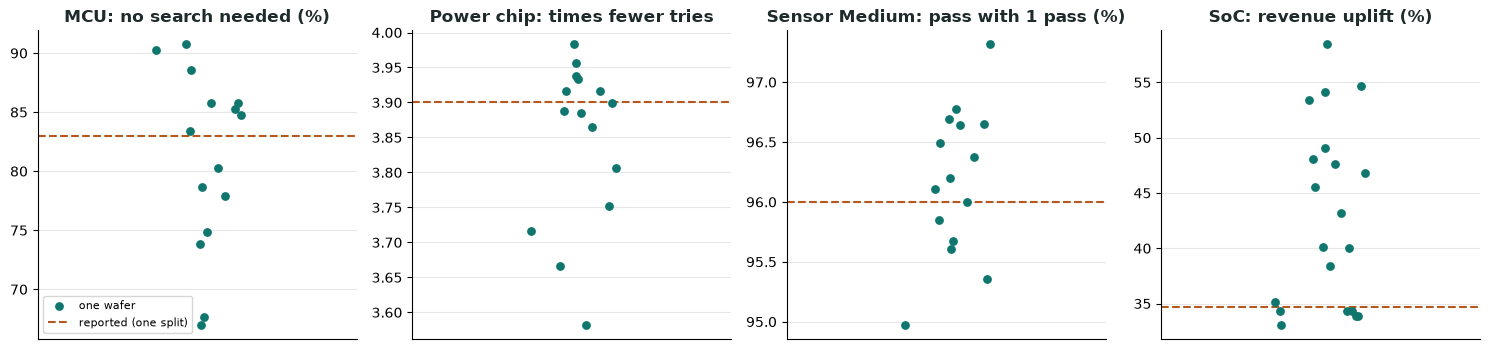

In [9]:
def rng(s):
    return s.median(), s.min(), s.max()

def line(metric, reported, s, n, unit="%", note=""):
    med, lo, hi = rng(s)
    f = (lambda v: f"{v:.1f}{unit}") if unit != "x" else (lambda v: f"{v:.1f}x")
    return {"result": metric, "reported (one split)": f(reported), "median across wafers": f(med),
            "range (worst to best wafer)": f"{f(lo)} to {f(hi)}", "wafers": n, "note": note}

rep_mcu = lowo_mcu[lowo_mcu.in_reported_test]
p1 = lowo_pmic[lowo_pmic["product"] == "PMIC-P1"]
s2 = lowo_sensor[lowo_sensor["product"] == "ACC-2G"]
summary = pd.DataFrame([
    line("MCU: chips needing no search", 83.0, lowo_mcu["no_search_%"], len(lowo_mcu)),
    line("MCU: tuning speed-up", 3.9, lowo_mcu.speedup_x, len(lowo_mcu), "x"),
    line("Power chip: fewer tries", 3.9, p1.fewer_tries_x, len(p1), "x"),
    line("Power chip P2/C7 (new versions): fewer tries", 3.9, lowo_pmic[lowo_pmic["product"] != "PMIC-P1"].fewer_tries_x,
         int((lowo_pmic["product"] != "PMIC-P1").sum()), "x", "never trained on these versions"),
    line("Sensor: pass with 1 oven pass (Medium)", 96.0, s2["Medium_%"], len(s2)),
    line("Sensor: pass with 1 oven pass (Tight)", 69.3, s2["Tight_%"], len(s2), note="tight grade keeps the 3-temperature test"),
    line("Sensor 8G/16G (new versions), Medium", 96.0, lowo_sensor[lowo_sensor["product"] != "ACC-2G"]["Medium_%"],
         int((lowo_sensor["product"] != "ACC-2G").sum()), note="2-3 wafers per version"),
    line("SoC: revenue from the plan, per wafer", WEEK_UPLIFT, lowo_soc["uplift_%"], len(lowo_soc),
         note=f"weekly plan over all wafers: +{WEEK_UPLIFT:.1f}%"),
    line("MCU-C: final-test pass with drift fix", 99.8, pd.concat([lowo_drift["fine_tuned_min_%"], lowo_drift["fine_tuned_max_%"]]),
         2, note="only 2 wafers: early result"),
])
print(summary.to_string(index=False))

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, (title, s, rep, unit) in zip(ax, [("MCU: no search needed (%)", lowo_mcu["no_search_%"], 83.0, "%"),
                                         ("Power chip: times fewer tries", p1.fewer_tries_x, 3.9, "x"),
                                         ("Sensor Medium: pass with 1 pass (%)", s2["Medium_%"], 96.0, "%"),
                                         ("SoC: revenue uplift (%)", lowo_soc["uplift_%"], 34.7, "%")]):
    a.scatter(np.random.RandomState(0).uniform(-.15, .15, len(s)), s, color=TEAL, s=28, zorder=3, label="one wafer")
    a.axhline(rep, color=COPPER, ls="--", label="reported (one split)")
    a.set(title=title, xticks=[], xlim=(-.5, .5))
ax[0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

# Part 2: Was each choice tuned for the real goal?
## 2.1 Trims: choose the model setting by **test time**, not by accuracy
Notebook 01 picked the HSI clock model (the hardest trim) by accuracy. The real goal is tester time, and the quality
limit is protected by design (in this simulation): every predicted code is **checked** before it is accepted, and a chip that fails the check
gets the conventional full search. So we compare 5 Random Forest settings with grouped cross-validation on the training wafers,
scored both ways.

In [10]:
A_train = A[~A.wafer_id.isin(REPORTED_TEST)].reset_index(drop=True)
A_test = A[A.wafer_id.isin(REPORTED_TEST)].reset_index(drop=True)
c, feats = TRIMS["hsi"], TRIM["hsi"]["features"]
SETTINGS = {"saved (600 trees, depth 10)": dict(n_estimators=600, max_depth=10, min_samples_leaf=2, max_features=1.0),
            "300 trees, no depth limit": dict(n_estimators=300, max_depth=None, min_samples_leaf=2, max_features=1.0),
            "300 trees, depth 16, 70% features": dict(n_estimators=300, max_depth=16, min_samples_leaf=4, max_features=0.7),
            "200 trees, depth 10, 50% features": dict(n_estimators=200, max_depth=10, min_samples_leaf=8, max_features=0.5),
            "400 trees, depth 24, leaf 1": dict(n_estimators=400, max_depth=24, min_samples_leaf=1, max_features=1.0)}
rows = []
for name, p in SETTINGS.items():
    w1, ms = [], []
    for tr_i, va_i in GroupKFold(n_splits=5).split(A_train, groups=A_train.wafer_id):
        tr, va = A_train.iloc[tr_i], A_train.iloc[va_i]
        m = RandomForestRegressor(random_state=SEED, n_jobs=-1, **p).fit(tr[feats], tr[c["label"]])
        err = to_code(m.predict(va[feats]), c["bits"]) - va[c["label"]].values
        w1.append((np.abs(err) <= 1).mean() * 100)
        ms.append((tries(err, c["bits"]) * c["ms"]).mean())
    rows.append({"setting": name, "within_1_step_%": np.mean(w1), "HSI_ms_per_chip": np.mean(ms)})
obj = pd.DataFrame(rows)
obj["rank_by_accuracy"] = obj["within_1_step_%"].rank(ascending=False).astype(int)
obj["rank_by_test_time"] = obj["HSI_ms_per_chip"].rank().astype(int)
print(obj.round(3).to_string(index=False))
pick = obj.sort_values("HSI_ms_per_chip").setting.iloc[0]
m = RandomForestRegressor(random_state=SEED, n_jobs=-1, **SETTINGS[pick]).fit(A_train[feats], A_train[c["label"]])
err = to_code(m.predict(A_test[feats]), c["bits"]) - A_test[c["label"]].values
saved_err = to_code(TRIM["hsi"]["model"].predict(A_test[feats]), c["bits"]) - A_test[c["label"]].values
print(f"\nPicked by test time: {pick}")
print(f"On the untouched test wafers: {(tries(err, c['bits']) * c['ms']).mean():.2f} ms per chip for the HSI trim "
      f"(saved model: {(tries(saved_err, c['bits']) * c['ms']).mean():.2f} ms; today: {A_test[c['conv']].mean() * c['ms']:.2f} ms)")
print("After the check, 100 % of chips are inside the trim spec: a wrong code is never accepted.")

                          setting  within_1_step_%  HSI_ms_per_chip  rank_by_accuracy  rank_by_test_time
      saved (600 trees, depth 10)           80.459            5.283                 3                  3
        300 trees, no depth limit           80.586            5.268                 2                  1
300 trees, depth 16, 70% features           80.602            5.274                 1                  2
200 trees, depth 10, 50% features           80.214            5.335                 4                  4
      400 trees, depth 24, leaf 1           80.143            5.337                 5                  5



Picked by test time: 300 trees, no depth limit
On the untouched test wafers: 4.87 ms per chip for the HSI trim (saved model: 4.82 ms; today: 15.21 ms)
After the check, 100 % of chips are inside the trim spec: a wrong code is never accepted.


## 2.2 How many extra steps should the tester try before falling back?
`budget` = how many extra one-step moves the tester may try after the first check, before it gives up and runs
today's full search. Scored on the untouched test wafers with the saved models (MCU: all 3 trims; power chip: the
4 output rails, against 6.33 binary-search steps per rail today).

In [11]:
P1_test_f = P1[P1.wafer_id.isin(set(P1_test.wafer_id))]
rows = []
for b in range(4):
    e = mcu_errors(A_test, {t: TRIM[t]["model"] for t in TRIMS}, budget=b)
    fb = ~np.all([np.abs(e[t]) <= b for t in TRIMS], axis=0)
    rows.append({"chip": "MCU", "budget": b, "tries_per_chip": e.tries_ai.mean(), "today": e.tries_today.mean(),
                 "fallback_%": fb.mean() * 100, "ms_per_chip": e.ms_ai.mean()})
    p = pmic_errors(P1_test_f, saved_rails, PMIC_B["thresholds"]["vref"]["model"], budget=b)
    fbp = ~np.all([np.abs(p[r]) <= b for r in RAILS], axis=0)  # the 4 output rails, as on the website
    rows.append({"chip": "Power chip", "budget": b, "tries_per_chip": sum(tries(p[r], 6, b) for r in RAILS).mean(),
                 "today": 4 * 6.33, "fallback_%": fbp.mean() * 100, "ms_per_chip": np.nan})
budget = pd.DataFrame(rows)
print(budget.round(2).to_string(index=False))

      chip  budget  tries_per_chip  today  fallback_%  ms_per_chip
       MCU       0            7.50  19.80       58.02        11.73
Power chip       0           16.76  25.32       93.76          NaN
       MCU       1            4.72  19.80       16.98         7.37
Power chip       1            7.28  25.32       20.66          NaN
       MCU       2            4.20  19.80        6.65         6.34
Power chip       2            6.38  25.32        0.54          NaN
       MCU       3            4.00  19.80        1.48         5.93
Power chip       3            6.36  25.32        0.00          NaN


## 2.3 SoC: choose the speed safety margin on **validation** wafers, then check it on untouched wafers
Notebook 04 picked the 80 MHz margin from a sweep on its test wafers, so that test result was not independent.
Here the training wafers are split again: models are fitted on 11 wafers, the margin is chosen on 4 **validation**
wafers, and only then are the 5 **test** wafers scored. Two selection rules, both set on validation:

* **Rule A:** the smallest margin with escapes (chips sold as something they can't meet) **at or below 0.1 %**
* **Rule B:** the smallest margin with **zero** escapes

Wafers: fit 11 | validation 4 | test 5


Rule A (<= 0.1 % on validation): 60 MHz -> escapes validation 0.08 % | untouched test 0.32 % (5 of 1540 chips; true rate below 0.68 % with 95 % confidence)
Rule B (zero on validation): 80 MHz -> escapes validation 0.00 % | untouched test 0.00 % (0 of 1540 chips; true rate below 0.19 % with 95 % confidence)

Skipping the speed test for every chip at 80 MHz: saves $0.023 of tester time per chip but loses $3.70 of revenue per chip -> KEEP the speed test for this approach


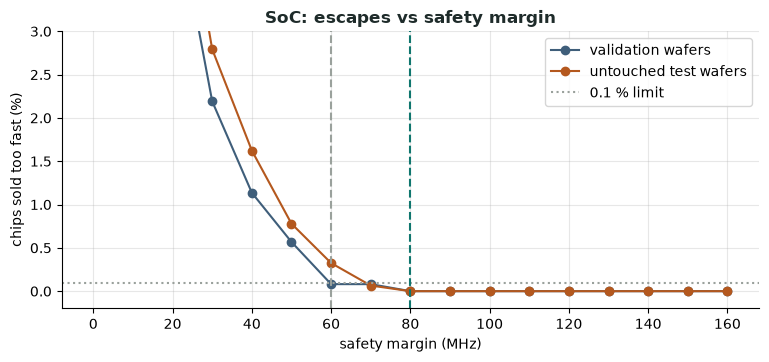

In [12]:
S_train, S_test = wafer_split(soc)
i_tr, i_va = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(S_train, groups=S_train.wafer_id))
S_in, S_val = S_train.iloc[i_tr].reset_index(drop=True), S_train.iloc[i_va].reset_index(drop=True)
inner = {k: clone(SOC_B["speed_models"][k]).fit(S_in.loc[S_in[f"f_top{k}"].notna(), SOC_B["features"]],
                                                S_in.loc[S_in[f"f_top{k}"].notna(), f"f_top{k}"]) for k in KS}
print(f"Wafers: fit {S_in.wafer_id.nunique()} | validation {S_val.wafer_id.nunique()} | test {S_test.wafer_id.nunique()}")
SPEED_TEST_MS = float(soc.conv_speed_test_time_ms.mean())
TESTER_USD_PER_S = 0.05
MARGINS = list(range(0, 161, 10))

def sweep(d, ft):
    true_el = eligibility(d, measured(d))
    true_sku = best_sku(true_el)
    full = pd.Series(true_sku).map(PRICE).fillna(0).mean()
    out = []
    for g in MARGINS:
        pe = eligibility(d, ft, g / 1000)            # pessimistic: predicted speed minus the margin
        ps = best_sku(pe)
        po = best_sku(eligibility(d, ft, -g / 1000))  # optimistic: predicted speed plus the margin
        unsure = ps != po                             # the margin is wider than the distance to a product boundary
        esc_g, esc_h = unsafe(ps, pe, true_el), unsafe(ps, pe, true_el) & ~unsure
        hyb = np.where(unsure, true_sku, ps)
        out.append({"margin_MHz": g, "chips": len(d),
                    "guard_escapes": int(esc_g.sum()), "guard_escape_%": esc_g.mean() * 100,
                    "guard_revenue_%": pd.Series(ps).map(PRICE).fillna(0).mean() / full * 100,
                    "hybrid_tested_%": unsure.mean() * 100, "hybrid_escapes": int(esc_h.sum()),
                    "hybrid_escape_%": esc_h.mean() * 100,
                    "hybrid_revenue_%": pd.Series(hyb).map(PRICE).fillna(0).mean() / full * 100})
    return pd.DataFrame(out)

val_curve, test_curve = sweep(S_val, predicted(S_val, inner)), sweep(S_test, predicted(S_test, SOC_B["speed_models"]))
rule_a = int(val_curve[val_curve["guard_escape_%"] <= 0.1].margin_MHz.min())
rule_b = int(val_curve[val_curve["guard_escapes"] == 0].margin_MHz.min())
for name, g in [("Rule A (<= 0.1 % on validation)", rule_a), ("Rule B (zero on validation)", rule_b)]:
    v, t = val_curve.set_index("margin_MHz").loc[g], test_curve.set_index("margin_MHz").loc[g]
    print(f"{name}: {g} MHz -> escapes validation {v['guard_escape_%']:.2f} % | untouched test {t['guard_escape_%']:.2f} % "
          f"({int(t.guard_escapes)} of {int(t.chips)} chips; true rate below {upper95(int(t.guard_escapes), int(t.chips)) * 100:.2f} % with 95 % confidence)")
GUARD = rule_b
t = test_curve.set_index("margin_MHz").loc[GUARD]
saved = SPEED_TEST_MS / 1000 * TESTER_USD_PER_S
lost = (100 - t["guard_revenue_%"]) / 100 * pd.Series(best_sku(eligibility(S_test, measured(S_test)))).map(PRICE).fillna(0).mean()
print(f"\nSkipping the speed test for every chip at {GUARD} MHz: saves ${saved:.3f} of tester time per chip but loses "
      f"${lost:.2f} of revenue per chip -> {'skip the test' if saved > lost else 'KEEP the speed test for this approach'}")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(val_curve.margin_MHz, val_curve["guard_escape_%"], "o-", color=SLATE, label="validation wafers")
ax.plot(test_curve.margin_MHz, test_curve["guard_escape_%"], "o-", color=COPPER, label="untouched test wafers")
ax.axhline(0.1, color=GREY, ls=":", label="0.1 % limit"); ax.axvline(rule_a, color=GREY, ls="--"); ax.axvline(rule_b, color=TEAL, ls="--")
ax.set(xlabel="safety margin (MHz)", ylabel="chips sold too fast (%)", title="SoC: escapes vs safety margin", ylim=(-.2, 3))
ax.legend(); plt.show()

# Part 3: Does each method beat today's way?
One row per task. **Baseline** is today's flow, the physics formula or the existing rule. The method is kept only
where it improves the engineering result. Rows marked *notebook 0X* repeat the result from that notebook; the others
are computed here (medians across wafers from Part 1).

In [13]:
pm_p1 = lowo_pmic[lowo_pmic["product"] == "PMIC-P1"]
baselines = pd.DataFrame([
    ["MCU trims", "today's binary search / physics formula", "Random Forest, predict then check",
     "tries per chip", f"{lowo_mcu.tries_today.median():.1f}", f"{lowo_mcu.tries_ai.median():.1f}", "Keep ML", "here"],
    ["MCU trims", "physics formula", "Random Forest", "chips needing no search",
     f"{lowo_mcu['formula_no_search_%'].median():.0f}%", f"{lowo_mcu['no_search_%'].median():.0f}%", "Keep ML", "here"],
    ["MCU-C final test", "trim to 1.200 V", "drift-aware target (fine-tuned)", "final-test pass",
     f"{lowo_drift['today_%'].mean():.1f}%", f"{lowo_drift['fine_tuned_median_%'].mean():.1f}%", "Keep (early: 2 wafers)", "here"],
    ["MCU fuse maps", "burn as generated (no check)", "rules from the fuse schema", "bad maps burned", "406 of 406",
     "0 (no false alarms)", "Keep rules", "notebook 00/01"],
    ["Power-chip rails", "today's binary search", "Ridge from one reference reading", "tries per chip",
     f"{pm_p1.tries_today.median():.1f}", f"{pm_p1.tries_ai.median():.1f}", "Keep ML", "here"],
    ["Power-chip customer settings", "ML on raw fields", "datasheet rules", "requests judged right", "96-98.5%", "100%",
     "Keep rules", "notebook 02"],
    ["Power-chip current sense", "2-point formula", "Ridge (2 points + process data)", "worst error (mA)", "6.6", "3.3",
     "Keep ML", "notebook 02"],
    ["Sensor calibration", "fleet average (1 insertion)", "Ridge from 25 C data", "pass, Medium grade",
     f"{s2['Medium_fleet_%'].median():.0f}%", f"{s2['Medium_%'].median():.0f}%", "Keep ML (not Tight grade)", "here"],
    ["SoC product mix", "best product each chip qualifies for", "integer program vs demand", "revenue",
     "100%", f"+{WEEK_UPLIFT:.1f}% (every wafer +{lowo_soc['uplift_%'].min():.0f}% or more)", "Keep optimiser", "here"],
    ["SoC speed (all chips)", "450 ms speed test", f"Ridge + {GUARD} MHz margin, no test", "revenue vs full test",
     "100%", f"{test_curve.set_index('margin_MHz').loc[GUARD, 'guard_revenue_%']:.1f}%", "Reject (costs more than it saves)", "here"],
    ["SoC memory repair", "greedy repair", "exact branch and bound", "arrays repaired (of 3,000)", "1,843", "1,860",
     "Keep exact", "notebook 04"],
], columns=["task", "baseline", "method", "measure", "baseline value", "method value", "decision", "source"])
print(baselines.to_string(index=False))

                        task                                baseline                            method                    measure baseline value                      method value                          decision         source
                   MCU trims today's binary search / physics formula Random Forest, predict then check             tries per chip           19.8                               4.8                           Keep ML           here
                   MCU trims                         physics formula                     Random Forest    chips needing no search            70%                               83%                           Keep ML           here
            MCU-C final test                         trim to 1.200 V   drift-aware target (fine-tuned)            final-test pass          90.7%                             99.4%            Keep (early: 2 wafers)           here
               MCU fuse maps            burn as generated (no check)        rules from t

# Part 4: Unusual and borderline chips
## 4.1 Out-of-range check: is this chip like the ones the model learned from?
For every input of a model we store the range seen in training (0.1 to 99.9 percentile, widened by 10 %). A chip with
any input outside it is sent straight to today's method instead of trusting the prediction.

In [14]:
INPUTS = {"MCU": ["bg_untrim_V", "hsi_untrim_MHz", "ldo_untrim_V", "bg_trimmed_sort_V"] + PCM + POS,
          "Power chip": ["vref_untrim_V", "vref_trimmed_sort_V"] + PCM + POS,
          "Sensor": ["offset_25C_mg", "sens_25C_rel", "st_response_mg", "stress_gauge_mV", "asic_vref_mV",
                     "mems_resonance_kHz", "mems_q_factor"] + PCM + POS,
          "SoC": ["ro_freq_MHz", "cpm_path_delay_ps", "iddq_25C_mA"] + PCM + POS}

def fit_range(d, cols, pad=0.10):
    lo, hi = d[cols].quantile(0.001), d[cols].quantile(0.999)
    return pd.DataFrame({"low": lo - pad * (hi - lo), "high": hi + pad * (hi - lo)})

def outside(d, rng):
    v = d[rng.index]
    return ((v < rng.low) | (v > rng.high)).any(axis=1).values

S_tr2 = SL[(SL.derivative == "ACC-2G") & SL.characterized_3temp]
S_tr2 = S_tr2[~S_tr2.wafer_id.isin(set(wafer_split(sensor[sensor.derivative == "ACC-2G"])[1].wafer_id))]
RANGES = {"MCU": fit_range(A_train, INPUTS["MCU"]), "Power chip": fit_range(P1[~P1.wafer_id.isin(set(P1_test.wafer_id))], INPUTS["Power chip"]),
          "Sensor": fit_range(S_tr2, INPUTS["Sensor"]), "SoC": fit_range(S_train, INPUTS["SoC"])}
saved_trim = {t: TRIM[t]["model"] for t in TRIMS}
e_mcu_base = mcu_errors(A_test, saved_trim)
rows = []
for chip, groups in [("MCU", [("MCU-A test wafers", A_test), ("MCU-B (new)", mcu_features(mcu[mcu.derivative == "MCU-B"])),
                               ("MCU-C (new)", mcu_features(mcu[mcu.derivative == "MCU-C"]))]),
                     ("Power chip", [("PMIC-P1 test wafers", P1_test_f), ("PMIC-P2 (new)", NEW[NEW.derivative == "PMIC-P2"]),
                                     ("PMIC-C7 (new)", NEW[NEW.derivative == "PMIC-C7"])])]:
    for name, d in groups:
        e = mcu_errors(d, saved_trim) if chip == "MCU" else pmic_errors(d, saved_rails, PMIC_B["thresholds"]["vref"]["model"])
        flag = outside(d, RANGES[chip])
        rows.append({"chip": chip, "group": name, "chips": len(d), "out_of_range_%": flag.mean() * 100,
                     "fallback_if_trusted_%": (~e.no_search).mean() * 100,
                     "fallback_among_flagged_%": (~e.no_search[flag]).mean() * 100 if flag.any() else np.nan,
                     "fallback_among_normal_%": (~e.no_search[~flag]).mean() * 100})
for name, d in [("ACC-2G production", SL[(SL.derivative == "ACC-2G") & ~SL.characterized_3temp]),
                ("ACC-8G (new)", SL[SL.derivative == "ACC-8G"]), ("ACC-16G (new)", SL[SL.derivative == "ACC-16G"])]:
    rows.append({"chip": "Sensor", "group": name, "chips": len(d), "out_of_range_%": outside(d, RANGES["Sensor"]).mean() * 100})
rows.append({"chip": "SoC", "group": "test wafers", "chips": len(S_test), "out_of_range_%": outside(S_test, RANGES["SoC"]).mean() * 100})
ood = pd.DataFrame(rows)
print(ood.round(2).to_string(index=False))

      chip               group  chips  out_of_range_%  fallback_if_trusted_%  fallback_among_flagged_%  fallback_among_normal_%
       MCU   MCU-A test wafers   1684            0.24                  16.98                      0.00                    17.02
       MCU         MCU-B (new)   1263            0.48                  17.66                     16.67                    17.66
       MCU         MCU-C (new)    842           75.18                  21.97                     23.85                    16.27
Power chip PMIC-P1 test wafers   2212            0.09                  20.66                    100.00                    20.59
Power chip       PMIC-P2 (new)   1659            0.72                  19.65                     16.67                    19.67
Power chip       PMIC-C7 (new)   1106            4.97                  26.40                     29.09                    26.26
    Sensor   ACC-2G production  19983            1.19                    NaN                       NaN  

### Why are 3 in 4 MCU-C chips flagged, when the model works on them?

In [15]:
C_all = mcu_features(mcu[mcu.derivative == "MCU-C"])
r = RANGES["MCU"]
print("MCU-C inputs outside the MCU-A range (% of chips):",
      {c: round(((C_all[c] < r.low[c]) | (C_all[c] > r.high[c])).mean() * 100, 1) for c in r.index
       if ((C_all[c] < r.low[c]) | (C_all[c] > r.high[c])).any()})
# shadow mode: the first MCU-C wafer runs beside today's flow, then its readings are added to the allowed range
c1, c2 = (C_all[C_all.wafer_id == w] for w in sorted(C_all.wafer_id.unique()))
r2 = fit_range(pd.concat([A_train, c1]), INPUTS["MCU"])
e2 = mcu_errors(c2, saved_trim)
print(f"After shadow mode on {c1.wafer_id.iloc[0]}: flagged on {c2.wafer_id.iloc[0]} falls from "
      f"{outside(c2, r).mean() * 100:.0f}% to {outside(c2, r2).mean() * 100:.1f}%; its chips still fall back "
      f"{(~e2.no_search).mean() * 100:.0f}% of the time (MCU-A: {(~e_mcu_base.no_search).mean() * 100:.0f}%)")

MCU-C inputs outside the MCU-A range (% of chips): {'bg_untrim_V': np.float64(0.4), 'bg_trimmed_sort_V': np.float64(0.2), 'pcm_vth_p_mV': np.float64(1.0), 'pcm_tox_A': np.float64(68.5), 'pcm_mobility_rel': np.float64(15.8)}


After shadow mode on MC1-W01: flagged on MC1-W02 falls from 80% to 0.2%; its chips still fall back 25% of the time (MCU-A: 17%)


## 4.2 SoC: speed-test only the chips the AI is unsure about
Instead of one margin for every chip, each chip's product is worked out twice: with its predicted speed **minus** the
margin and **plus** the margin. If both give the same product, the chip is far from any product boundary and is
sold on the prediction (with the safer, pessimistic voltage bin). If they differ, the chip is close to a boundary and
gets the normal 450 ms speed test. The margin is chosen on validation wafers with Rule B (zero escapes), then
checked on the untouched test wafers.

Margin chosen on validation: 80 MHz
Untouched test wafers: speed-tested 15.1 % of chips, skipped 84.9 %
Escapes: 0 of 1540 chips (true rate below 0.19 % with 95 % confidence) | revenue 100.0 % of full testing
Speed-test time saved: about 382 ms per chip (full test 450 ms)


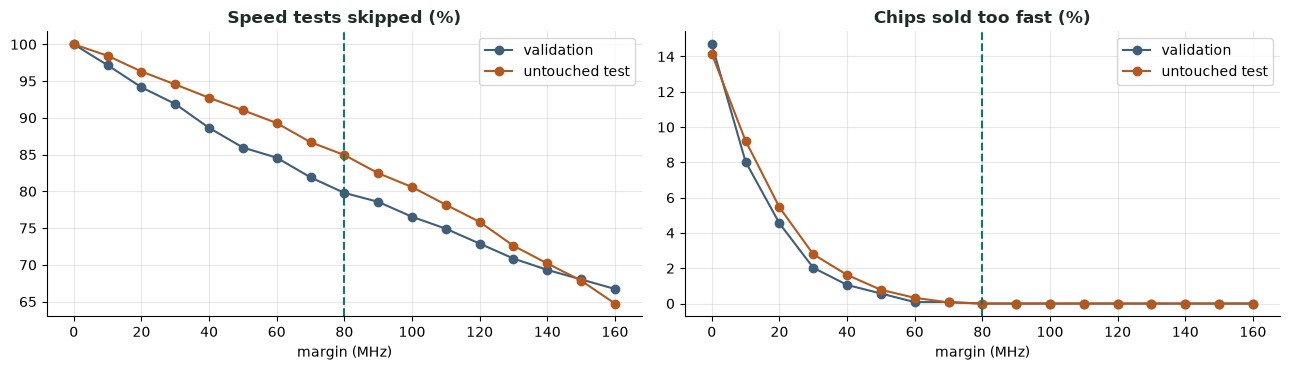

In [16]:
HYB = int(val_curve[val_curve["hybrid_escapes"] == 0].margin_MHz.min())
v, t = val_curve.set_index("margin_MHz").loc[HYB], test_curve.set_index("margin_MHz").loc[HYB]
print(f"Margin chosen on validation: {HYB} MHz")
print(f"Untouched test wafers: speed-tested {t['hybrid_tested_%']:.1f} % of chips, skipped {100 - t['hybrid_tested_%']:.1f} %")
print(f"Escapes: {int(t.hybrid_escapes)} of {int(t.chips)} chips (true rate below {upper95(int(t.hybrid_escapes), int(t.chips)) * 100:.2f} % "
      f"with 95 % confidence) | revenue {t['hybrid_revenue_%']:.1f} % of full testing")
print(f"Speed-test time saved: about {(100 - t['hybrid_tested_%']) / 100 * SPEED_TEST_MS:.0f} ms per chip "
      f"(full test {SPEED_TEST_MS:.0f} ms)")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for c_, d, lab in [(SLATE, val_curve, "validation"), (COPPER, test_curve, "untouched test")]:
    ax[0].plot(d.margin_MHz, 100 - d["hybrid_tested_%"], "o-", color=c_, label=lab)
    ax[1].plot(d.margin_MHz, d["hybrid_escape_%"], "o-", color=c_, label=lab)
ax[0].set(title="Speed tests skipped (%)", xlabel="margin (MHz)"); ax[1].set(title="Chips sold too fast (%)", xlabel="margin (MHz)")
for a in ax: a.axvline(HYB, color=TEAL, ls="--"); a.legend()
plt.tight_layout(); plt.show()

## 4.3 Fallback rates and the savings that remain

In [17]:
e_mcu = mcu_errors(A_test, saved_trim)
flag_mcu = outside(A_test, RANGES["MCU"])
e_pm = pmic_errors(P1_test_f, saved_rails, PMIC_B["thresholds"]["vref"]["model"])
flag_pm = outside(P1_test_f, RANGES["Power chip"])
mcu_ms_routed = np.where(flag_mcu, e_mcu.ms_today, e_mcu.ms_ai)
pm_routed = np.where(flag_pm, e_pm.tries_today, e_pm.tries_ai)
s_rows = SL[(SL.derivative == "ACC-2G") & ~SL.characterized_3temp]
fallback = pd.DataFrame([
    {"chip": "MCU", "sent to today's method": f"{(~e_mcu.no_search).mean() * 100:.1f}% fail the check + {flag_mcu.mean() * 100:.1f}% out of range",
     "today": f"{e_mcu.ms_today.mean():.1f} ms", "with AI and fallbacks": f"{mcu_ms_routed.mean():.1f} ms",
     "saved": f"{(1 - mcu_ms_routed.mean() / e_mcu.ms_today.mean()) * 100:.0f}%"},
    {"chip": "Power chip", "sent to today's method": f"{(~e_pm.no_search).mean() * 100:.1f}% fail the check + {flag_pm.mean() * 100:.1f}% out of range",
     "today": f"{e_pm.tries_today.mean():.1f} tries", "with AI and fallbacks": f"{pm_routed.mean():.1f} tries",
     "saved": f"{(1 - pm_routed.mean() / e_pm.tries_today.mean()) * 100:.0f}%"},
    {"chip": "Sensor", "sent to today's method": "Tight grade (all chips) + 5% sample for monitoring",
     "today": f"{sensor.conv_test_time_s.mean():.1f} s", "with AI and fallbacks": f"{0.95 * sensor.conv_test_time_s.mean() / 3 + 0.05 * sensor.conv_test_time_s.mean():.1f} s (Medium/Loose)",
     "saved": f"{(1 - (0.95 / 3 + 0.05)) * 100:.0f}%"},
    {"chip": "SoC", "sent to today's method": f"{t['hybrid_tested_%']:.1f}% near a product boundary get the speed test",
     "today": f"{SPEED_TEST_MS:.0f} ms", "with AI and fallbacks": f"{t['hybrid_tested_%'] / 100 * SPEED_TEST_MS:.0f} ms",
     "saved": f"{100 - t['hybrid_tested_%']:.0f}%"},
])
print(fallback.to_string(index=False))

      chip                             sent to today's method      today with AI and fallbacks saved
       MCU           17.0% fail the check + 0.2% out of range    28.7 ms                7.4 ms   74%
Power chip           20.7% fail the check + 0.1% out of range 44.6 tries            11.5 tries   74%
    Sensor Tight grade (all chips) + 5% sample for monitoring      7.2 s  2.6 s (Medium/Loose)   63%
       SoC   15.1% near a product boundary get the speed test     450 ms                 68 ms   85%


# Part 5: How it would run on a tester
## 5.1 One decision function per chip
The tester sends one chip's readings; the function answers with the codes to try and whether to trust them.

In [18]:
FAST = {t: copy.deepcopy(TRIM[t]["model"]).set_params(n_jobs=1) for t in TRIMS}  # one chip at a time: no thread start-up

def decide_mcu(chip: pd.DataFrame) -> dict:
    d = mcu_features(chip)
    if outside(d, RANGES["MCU"])[0]:
        return {"route": "today's full search", "why": "an input is outside the training range"}
    codes = {TRIMS[t]["name"]: int(to_code(FAST[t].predict(d[TRIM[t]["features"]]), TRIMS[t]["bits"])[0]) for t in TRIMS}
    return {"route": "set these codes, check once", "codes": codes}

typical = A_test[e_mcu.no_search.values & (e_mcu.tries_ai.values == 3)].iloc[[0]]
tricky = A_test[~e_mcu.no_search.values].iloc[[0]]
odd = A_test.iloc[[0]].copy(); odd["pcm_vth_n_mV"] += 10 * A_train.pcm_vth_n_mV.std()
for name, ch in [("typical chip", typical), ("tricky chip", tricky), ("unusual chip (shifted process)", odd)]:
    print(f"{name:32s} -> {decide_mcu(ch)}")
print("True codes of the tricky chip:", {TRIMS[t]["name"]: int(tricky[c["label"]].iloc[0]) for t, c in TRIMS.items()})

typical chip                     -> {'route': 'set these codes, check once', 'codes': {'Bandgap': 42, 'HSI clock': 28, 'LDO': 18}}
tricky chip                      -> {'route': 'set these codes, check once', 'codes': {'Bandgap': 42, 'HSI clock': 38, 'LDO': 18}}
unusual chip (shifted process)   -> {'route': "today's full search", 'why': 'an input is outside the training range'}
True codes of the tricky chip: {'Bandgap': 42, 'HSI clock': 36, 'LDO': 17}


## 5.2 Speed per chip

In [19]:
one = A_test.iloc[[5]]
t0 = time.perf_counter(); [decide_mcu(one) for _ in range(30)]; single_ms = (time.perf_counter() - t0) / 30 * 1000
batch = mcu_features(A_test.iloc[:1000])
t0 = time.perf_counter(); [FAST[t].predict(batch[TRIM[t]["features"]]) for t in TRIMS]; batch_ms = (time.perf_counter() - t0) * 1000 / len(batch)
print(f"One chip at a time: {single_ms:.1f} ms per chip | a whole wafer at once: {batch_ms:.3f} ms per chip")
print("Predicting a full wafer while the previous wafer is still on the prober keeps this off the test time.")

One chip at a time: 111.7 ms per chip | a whole wafer at once: 0.171 ms per chip
Predicting a full wafer while the previous wafer is still on the prober keeps this off the test time.


## 5.3 Monitoring: the fallback rate is the alarm
If the process drifts or a new version arrives, more chips fail the check and fall back. In the simulation, quality is protected (the
check catches them), and the rising fallback rate tells the team to retrain. Here the MCU model trained on MCU-A is
watched on new wafers of MCU-B and MCU-C, plus one wafer with a simulated tester fault (its voltmeter reading 4 mV high).

        product               wafer  fallback_%  alarm
     MCU-A test             MA1-W01        20.9  False
     MCU-A test             MA2-W05         9.3  False
     MCU-A test             MA3-W02        24.7  False
     MCU-A test             MA3-W04        13.1  False
          MCU-B             MB1-W01        11.9  False
          MCU-B             MB1-W02        18.5  False
          MCU-B             MB1-W03        22.6  False
          MCU-C             MC1-W01        19.0  False
          MCU-C             MC1-W02        24.9  False
simulated fault MA3-W04 +4 mV meter        85.0   True


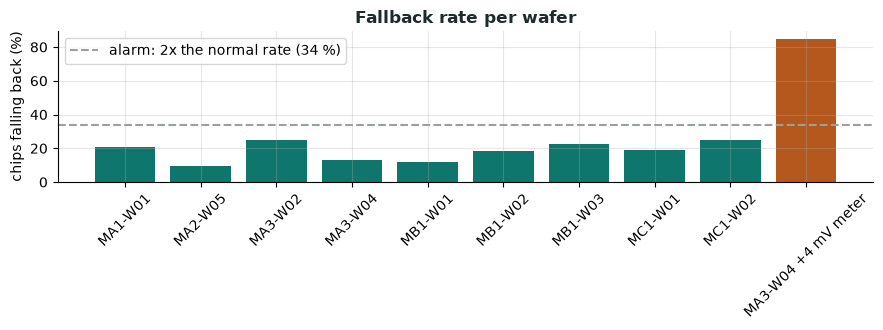

In [20]:
rows = []
for name, d in [("MCU-A test", A_test), ("MCU-B", mcu_features(mcu[mcu.derivative == "MCU-B"])), ("MCU-C", mcu_features(mcu[mcu.derivative == "MCU-C"]))]:
    e = mcu_errors(d, saved_trim)
    for w, idx in d.groupby("wafer_id").groups.items():
        rows.append({"product": name, "wafer": w, "fallback_%": (~e.loc[idx, "no_search"]).mean() * 100})
# a fault the model can't see: the tester's voltmeter reads 4 mV high on one wafer (the chips themselves are unchanged)
bad = A_test[A_test.wafer_id == A_test.wafer_id.iloc[-1]].copy()
bad["bg_untrim_V"] += 0.004
bad["ldo_untrim_V"] += 0.004
e = mcu_errors(mcu_features(bad), saved_trim)
rows.append({"product": "simulated fault", "wafer": bad.wafer_id.iloc[0] + " +4 mV meter", "fallback_%": (~e.no_search).mean() * 100})
mon = pd.DataFrame(rows)
ALARM = 2 * mon[mon["product"] == "MCU-A test"]["fallback_%"].median()
mon["alarm"] = mon["fallback_%"] > ALARM
print(mon.round(1).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(mon.wafer, mon["fallback_%"], color=[COPPER if a else TEAL for a in mon.alarm])
ax.axhline(ALARM, color=GREY, ls="--", label=f"alarm: 2x the normal rate ({ALARM:.0f} %)")
ax.set(title="Fallback rate per wafer", ylabel="chips falling back (%)"); ax.tick_params(axis="x", rotation=45); ax.legend()
plt.tight_layout(); plt.show()

## 5.4 Results by product version and by wafer zone (centre vs edge)

In [21]:
def zone(d, rmax):
    return np.where(d.radius_mm > 0.7 * rmax, "edge", "centre")

rows = []
for name, d in [("MCU-A test", A_test), ("MCU-B", mcu_features(mcu[mcu.derivative == "MCU-B"])), ("MCU-C", mcu_features(mcu[mcu.derivative == "MCU-C"]))]:
    e = mcu_errors(d, saved_trim)
    for z in ("centre", "edge"):
        m_ = zone(d, mcu.radius_mm.max()) == z
        rows.append({"model": "MCU trims", "product": name, "zone": z, "chips": int(m_.sum()), "no_search_%": e.no_search[m_].mean() * 100})
for name, d in [("PMIC-P1 test", P1_test_f), ("PMIC-P2", NEW[NEW.derivative == "PMIC-P2"]), ("PMIC-C7", NEW[NEW.derivative == "PMIC-C7"])]:
    e = pmic_errors(d, saved_rails, PMIC_B["thresholds"]["vref"]["model"])
    for z in ("centre", "edge"):
        m_ = zone(d, pmic.radius_mm.max()) == z
        rows.append({"model": "Power-chip rails", "product": name, "zone": z, "chips": int(m_.sum()), "no_search_%": e.no_search[m_].mean() * 100})
by_zone = pd.DataFrame(rows)
print(by_zone.pivot_table(index=["model", "product"], columns="zone", values="no_search_%").round(1).to_string())

zone                           centre  edge
model            product                   
MCU trims        MCU-A test      81.0  84.8
                 MCU-B           82.4  82.3
                 MCU-C           77.5  78.5
Power-chip rails PMIC-C7         75.3  72.1
                 PMIC-P1 test    79.6  79.1
                 PMIC-P2         81.9  79.0


## 5.5 Model cards

In [22]:
def r_(s, unit="%"):
    return f"{s.median():.0f}{unit} (wafers: {s.min():.0f}-{s.max():.0f}{unit})"

cards = pd.DataFrame([
    {"model": "MCU trims: Random Forest x3", "predicts": "bandgap, clock and regulator trim codes",
     "needs": "untrimmed readings, process monitors, position on wafer", "beats": "physics formula and today's search",
     "result": f"no search needed {r_(lowo_mcu['no_search_%'])}", "tested on": "15 MCU-A wafers, one at a time; MCU-B/C wafers",
     "falls back when": "the check fails, or an input is out of range"},
    {"model": "MCU-C drift: fine-tuned gradient boosting", "predicts": "voltage shift caused by packaging",
     "needs": "process monitors, position on wafer, 50 MCU-C chips to fine-tune", "beats": "trimming to 1.200 V",
     "result": f"final-test pass {lowo_drift['today_%'].mean():.0f}% -> {lowo_drift['fine_tuned_median_%'].mean():.1f}%",
     "tested on": "both MCU-C wafers, 20 samples each (early: 2 wafers)", "falls back when": "final test still catches any chip out of spec"},
    {"model": "Power-chip rails: Ridge x4", "predicts": "codes for the 4 output voltages",
     "needs": "one reference reading, process monitors, position", "beats": "today's search",
     "result": f"{p1.fewer_tries_x.median():.1f}x fewer tries (wafers: {p1.fewer_tries_x.min():.1f}-{p1.fewer_tries_x.max():.1f}x)",
     "tested on": "15 PMIC-P1 wafers one at a time; 5 wafers of P2/C7 never trained on", "falls back when": "the check fails, or an input is out of range"},
    {"model": "Sensor: Ridge x3", "predicts": "hot and cold behaviour from a room-temperature test",
     "needs": "25 C readings, self-test, process monitors", "beats": "the fleet-average single pass",
     "result": f"Medium grade pass {r_(s2['Medium_%'])}", "tested on": "15 ACC-2G wafers one at a time; 8G/16G wafers",
     "falls back when": "Tight grade: always the full 3-temperature test"},
    {"model": "SoC speed: Ridge x3 + margin", "predicts": "speed of the 4/6/8 fastest cores",
     "needs": "ring oscillator, path delay, leakage, good-core count, process monitors",
     "beats": "speed-testing every chip", "result": f"{100 - t['hybrid_tested_%']:.0f}% of speed tests skipped, {int(t.hybrid_escapes)} escapes",
     "tested on": f"margin chosen on {S_val.wafer_id.nunique()} validation wafers, checked on {S_test.wafer_id.nunique()} untouched wafers",
     "falls back when": f"the chip is within {HYB} MHz of a product boundary"},
])
for _, row in cards.iterrows():
    print(f"\n{row['model']}\n" + "\n".join(f"  {k:16s}: {v}" for k, v in row.items() if k != "model") + "\n  data            : synthetic")


MCU trims: Random Forest x3
  predicts        : bandgap, clock and regulator trim codes
  needs           : untrimmed readings, process monitors, position on wafer
  beats           : physics formula and today's search
  result          : no search needed 83% (wafers: 67-91%)
  tested on       : 15 MCU-A wafers, one at a time; MCU-B/C wafers
  falls back when : the check fails, or an input is out of range
  data            : synthetic

MCU-C drift: fine-tuned gradient boosting
  predicts        : voltage shift caused by packaging
  needs           : process monitors, position on wafer, 50 MCU-C chips to fine-tune
  beats           : trimming to 1.200 V
  result          : final-test pass 91% -> 99.4%
  tested on       : both MCU-C wafers, 20 samples each (early: 2 wafers)
  falls back when : final test still catches any chip out of spec
  data            : synthetic

Power-chip rails: Ridge x4
  predicts        : codes for the 4 output voltages
  needs           : one reference readin

## 5.6 Save the results for the website

In [23]:
def records(df):
    return json.loads(df.to_json(orient="records"))

out = {"note": "synthetic data", "lowo_mcu": records(lowo_mcu), "lowo_pmic": records(lowo_pmic),
       "lowo_sensor": records(lowo_sensor), "lowo_soc": records(lowo_soc), "lowo_drift": records(lowo_drift),
       "summary": records(summary), "objective": records(obj), "budget": records(budget),
       "soc_curve_validation": records(val_curve), "soc_curve_test": records(test_curve),
       "soc_rule_a_MHz": rule_a, "soc_rule_b_MHz": rule_b, "soc_hybrid_MHz": HYB, "speed_test_ms": SPEED_TEST_MS,
       "baselines": records(baselines), "ood": records(ood), "fallback": records(fallback), "monitoring": records(mon),
       "by_zone": records(by_zone), "model_cards": records(cards),
       "ranges": {k: {c: [float(r.low), float(r.high)] for c, r in v.iterrows()} for k, v in RANGES.items()}}
with open("evaluation_06.json", "w") as f:
    json.dump(out, f, indent=1)
print("Saved evaluation_06.json:", round(len(json.dumps(out)) / 1e3), "KB")

Saved evaluation_06.json: 39 KB


# Part 6: What this notebook changed, and what still holds

| Question | Answer | What changed |
|---|---|---|
| Stable from wafer to wafer? | **Mostly yes.** MCU: no search needed on 83% of chips in the median wafer, but the range is **67-91%**, so two wafers are clearly harder. Power chip: 3.6-4.0x fewer tries. Sensor (Medium): 95-97%. SoC plan: every wafer gains at least +33%. | Results are now quoted with their range, not as one number |
| New chip versions? | Power chip P2/C7: 3.5-3.9x, never trained on. Sensor 8G/16G: 96% (Medium). MCU-C drift fix: 99.0-99.8% in both directions, but **only 2 wafers**, so it stays an early result. The MCU-A model alone already reaches that pass rate; the 50 MCU-C chips mainly halve the shift error. | MCU-C claim worded as "early result" |
| Tuned for the real goal? | Trims: choosing by **test time** picks practically the same model as choosing by accuracy (all settings within 0.1 ms), so the saved model stays. Allowing 2-3 extra checks before falling back would save a bit more tester time; quality is the same either way. | Nothing to retrain; "extra checks" is now a what-if on the website |
| SoC safety margin | Choosing on **validation** wafers with "at most 0.1% escapes" picked 60 MHz, and the untouched wafers then showed **0.32% escapes**: worse than validation. Requiring **zero** escapes on validation picks **80 MHz**, which gave 0 of 1,540 escapes on untouched wafers (below 0.19% with 95% confidence). | The 80 MHz is now justified on validation data, not read off the test set |
| Beats today's way? | Yes for every kept method (Part 3). Two things are rejected on evidence: predicting SoC speed for **every** chip (loses $3.70 of revenue to save $0.02 of tester time per chip), and ML for fuse maps and customer settings (rules are exact). | One baseline table for all tasks |
| Unusual or borderline chips | **Speed-test only the chips near a product boundary:** 85% of SoC chips skip the 450 ms speed test, with 0 escapes and no revenue lost on untouched wafers. The out-of-range check flags almost nothing on the main products, but flags 3 in 4 MCU-C chips (a different oxide thickness), so ranges must be kept **per product version**, learned in shadow mode. | **New result for the SoC**, and a rule for new versions |
| Ready for a tester? | Predicting a whole wafer takes about 0.2 ms per chip, so it runs ahead of the test; one chip at a time is too slow (about 125 ms) for inline use. The fallback rate per wafer is the alarm: a simulated tester fault (voltmeter 4 mV high) trips it, while the real MCU-B/C wafers don't. | Deployment pattern: predict per wafer, check per chip, watch the fallback rate |

### The honest limit
Everything here is measured on **synthetic data**. These checks show the methods are stable **on these
generated datasets**. They can't show the same on real fab data. The next step is to repeat exactly these checks on
real wafers, with the AI in **shadow mode** (predicting beside today's flow, which still decides) before it is trusted.